# 17. S-Matrix Layer Mode Reuse Across Diverse Substrates & Thickness Averaging

## Physical Motivation & Learning Objectives
The modularity of the scattering-matrix method allows pre-computed layer eigenmodes to be reused across varying substrates and active layer thicknesses without re-solving the nanostructure field equations.
In this tutorial:
1. We compute 1D grating modes once.
2. We evaluate absorption across 10 different substrate refractive indices.
3. We average across multiple thicknesses to eliminate Fabry–Pérot interference fringes.



##################################################################
EMUstack is brought to you by Bjorn Sturmberg, Kokou Dossou, 
Felix Lawrence & Lindsay Botton, with support from CUDOS & ARENA
Starting EMUstack calculation ...
##################################################################



/home/giovi/projects/emustack_port/EMUstack/backend/plotting.py:428: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig = plt.figure(num=None, figsize=(9, 12))


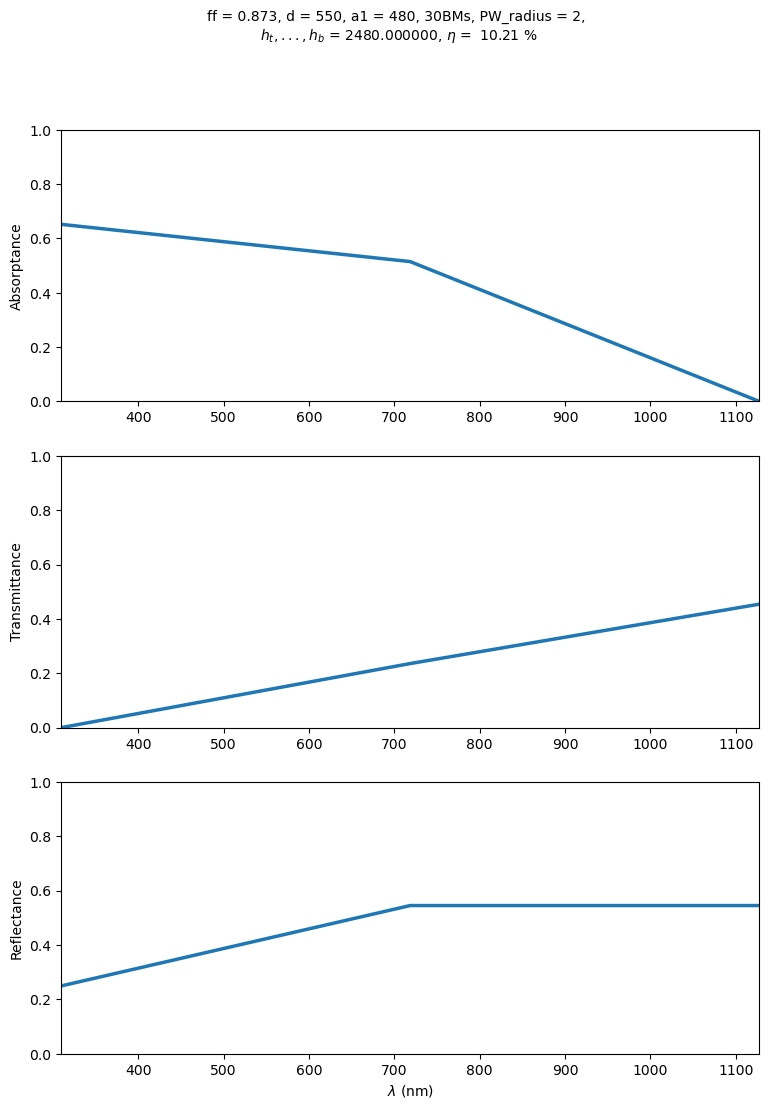

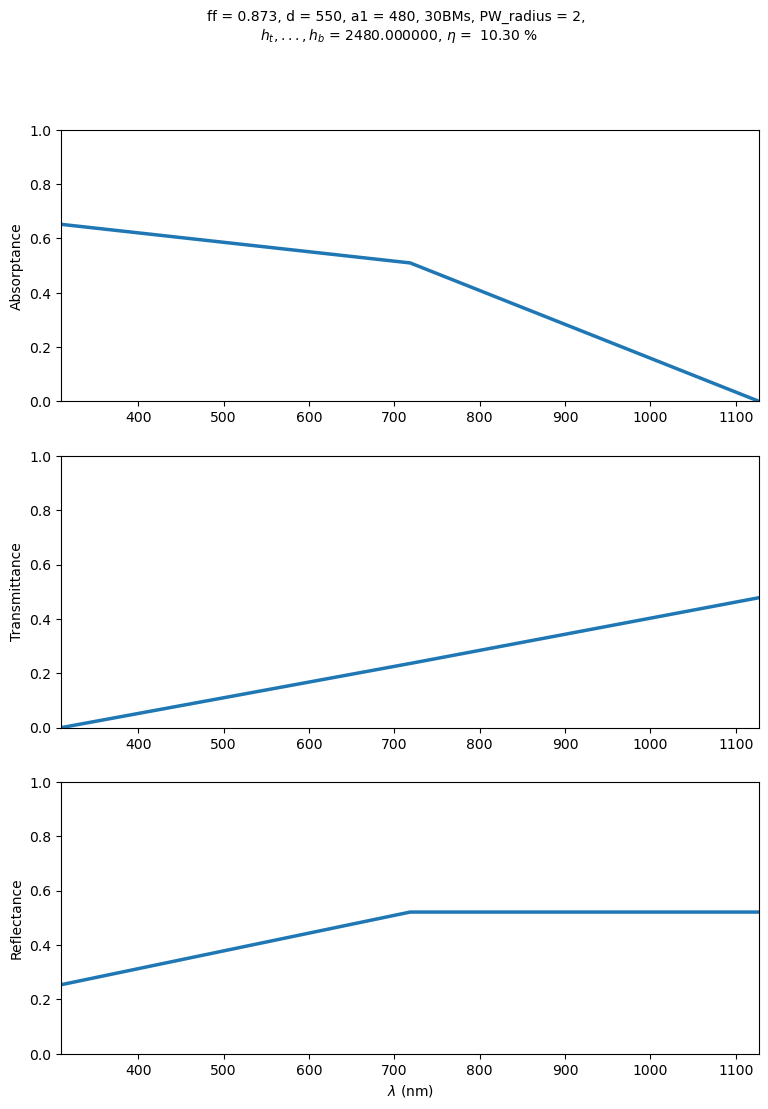

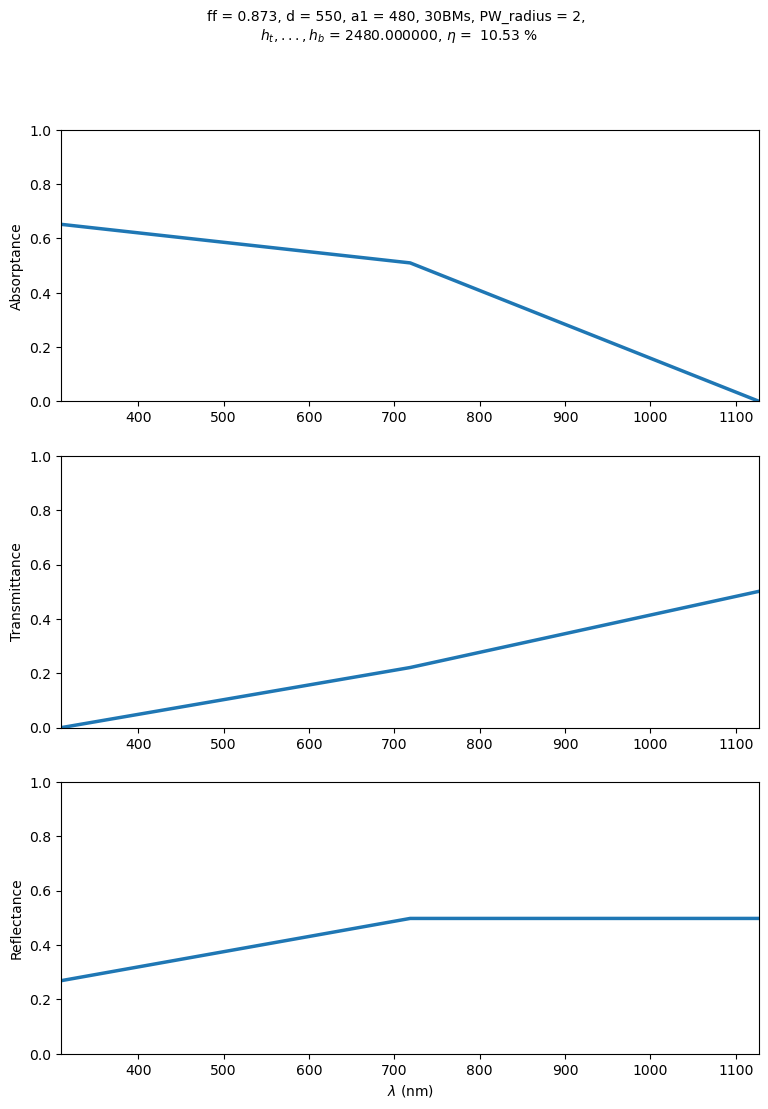

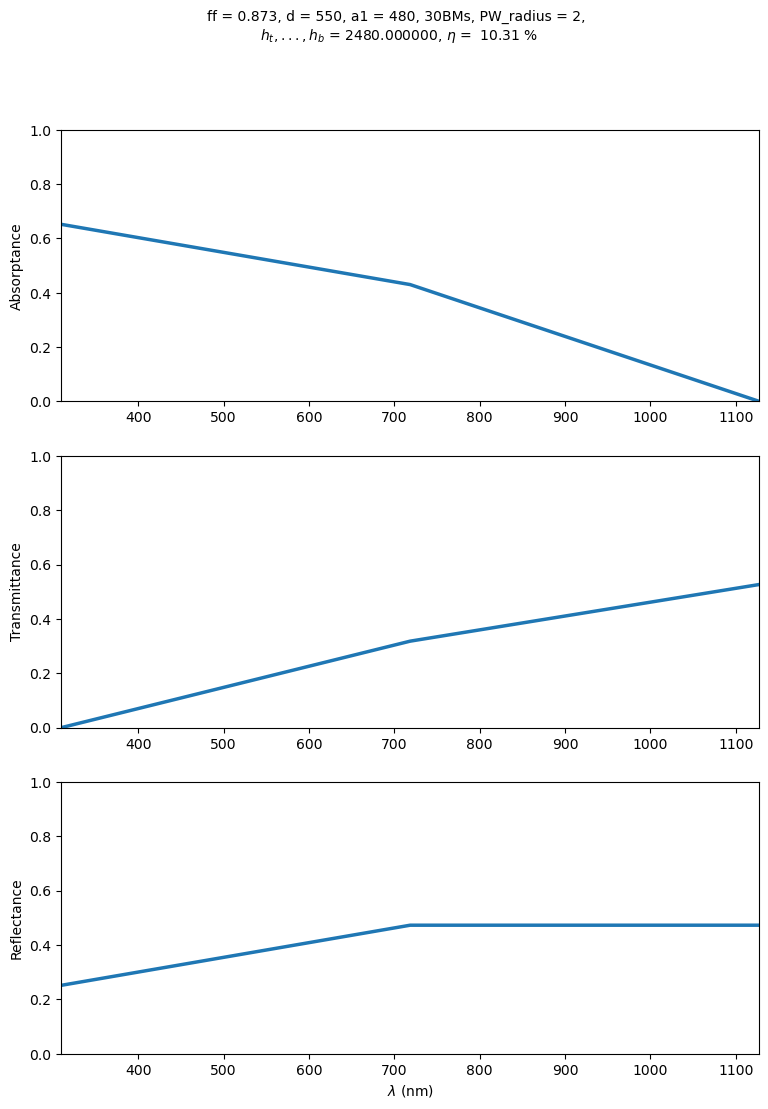

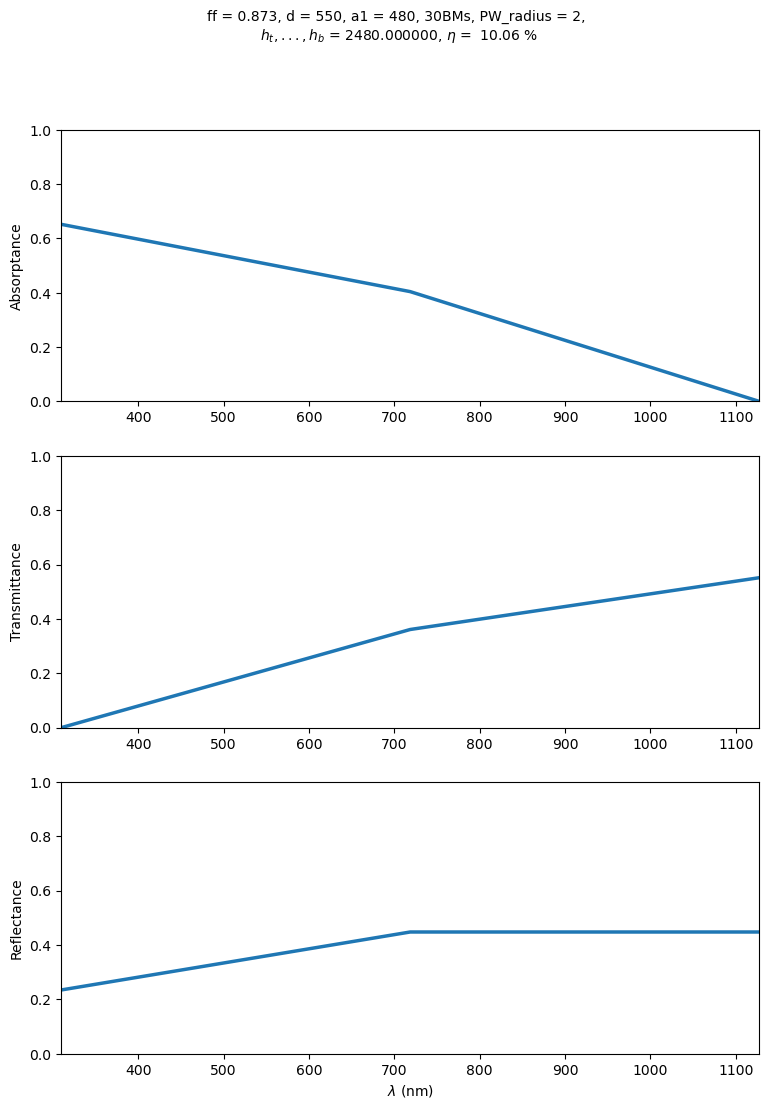

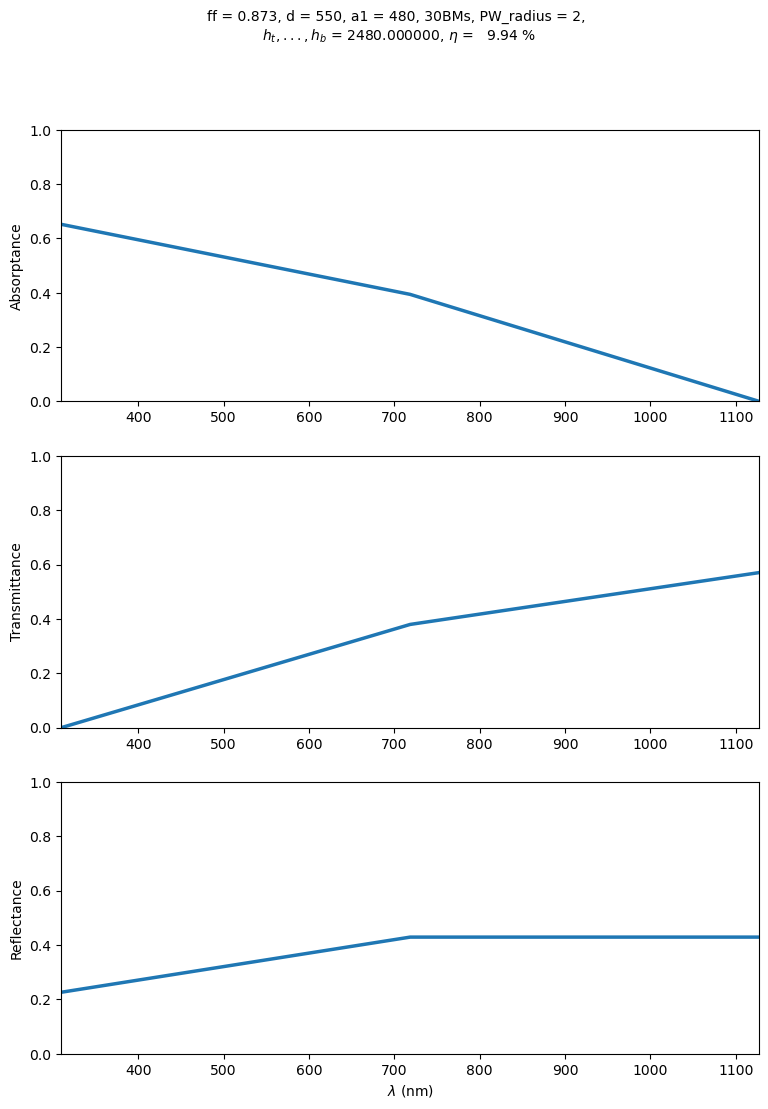

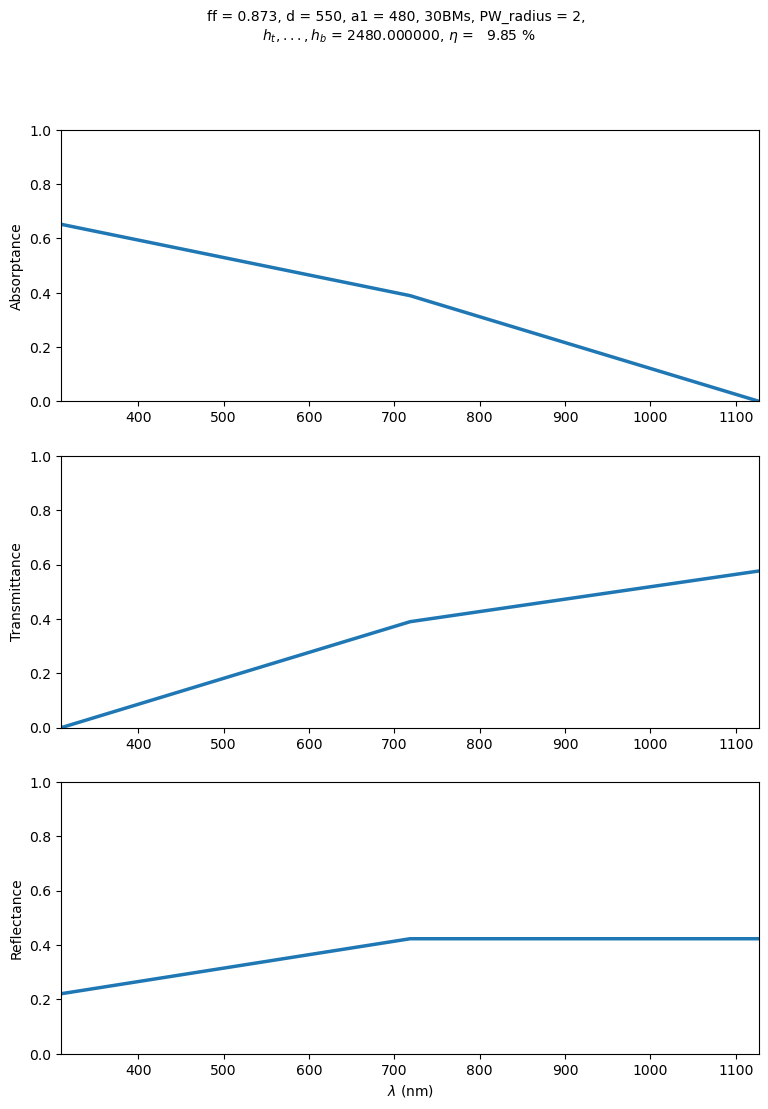

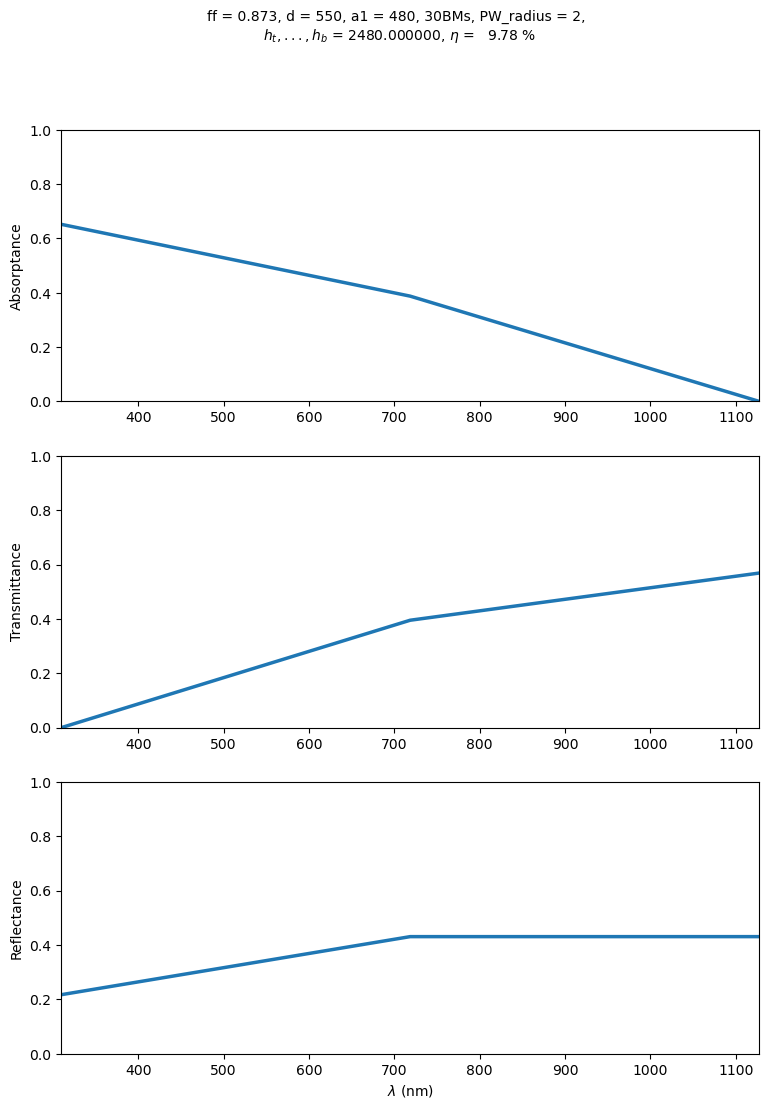

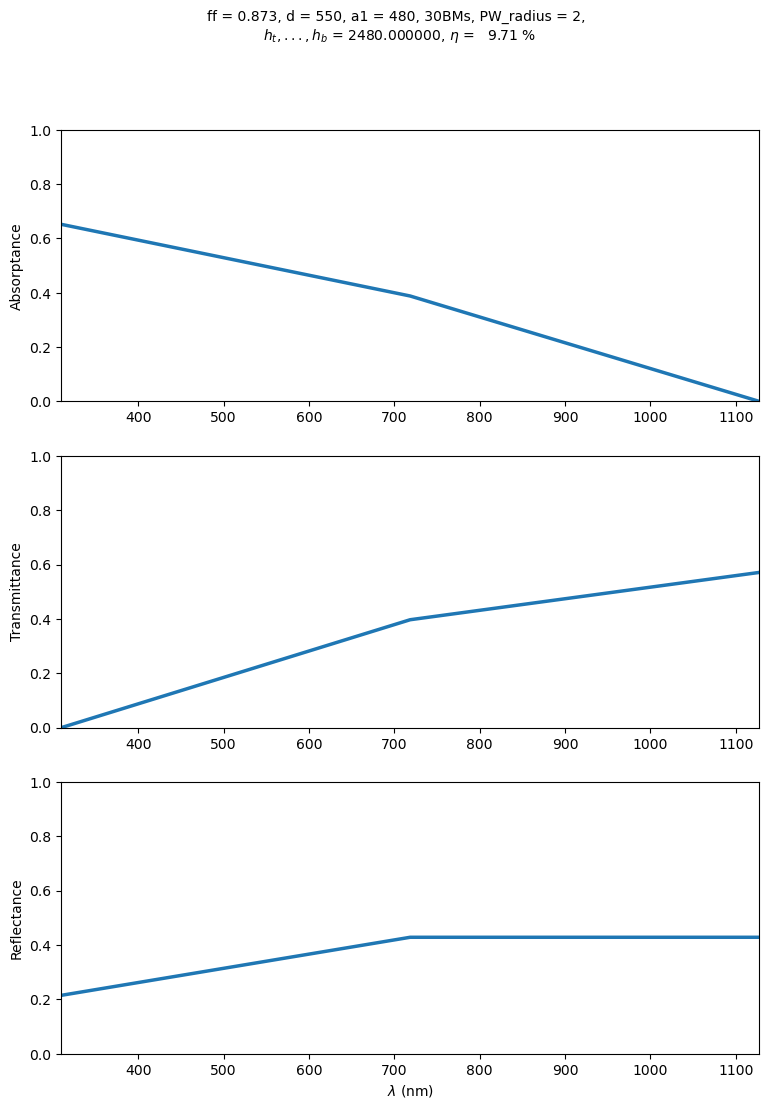

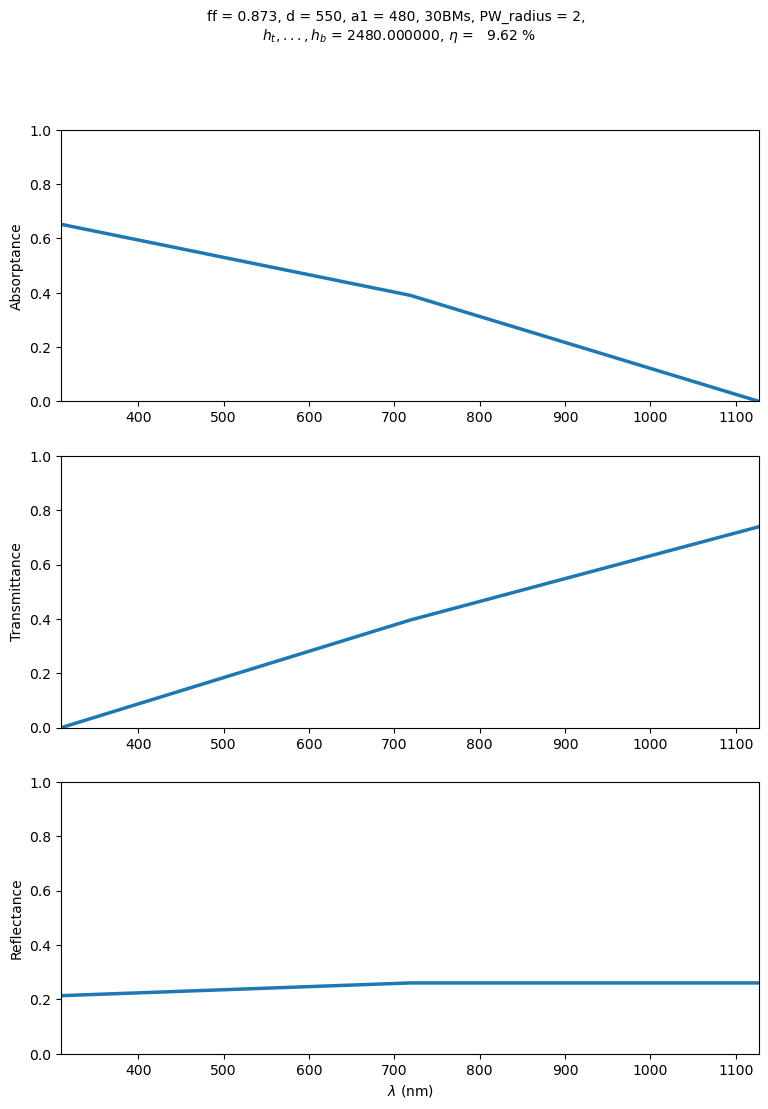

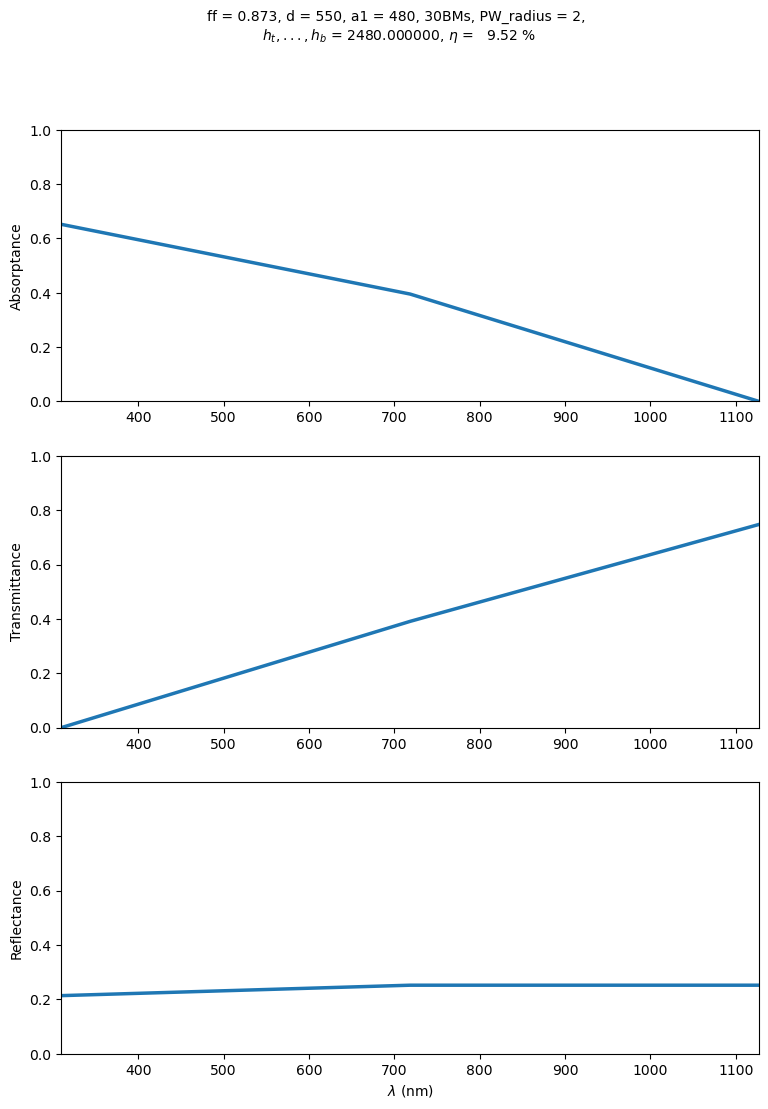

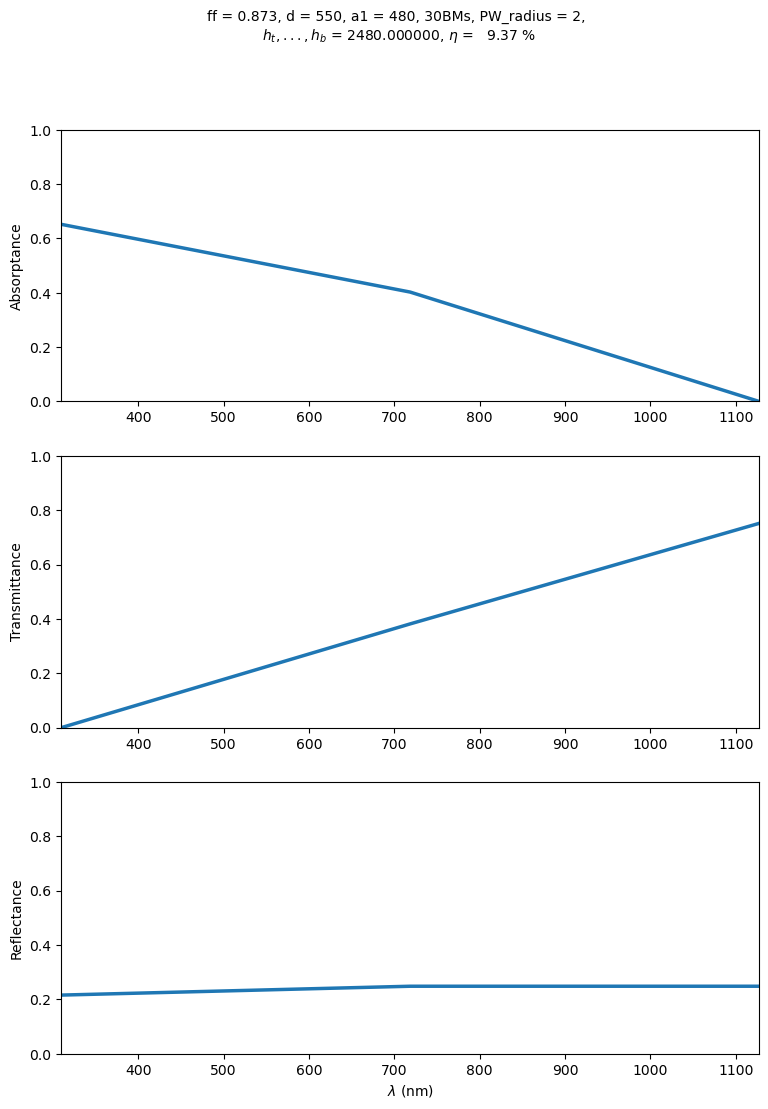

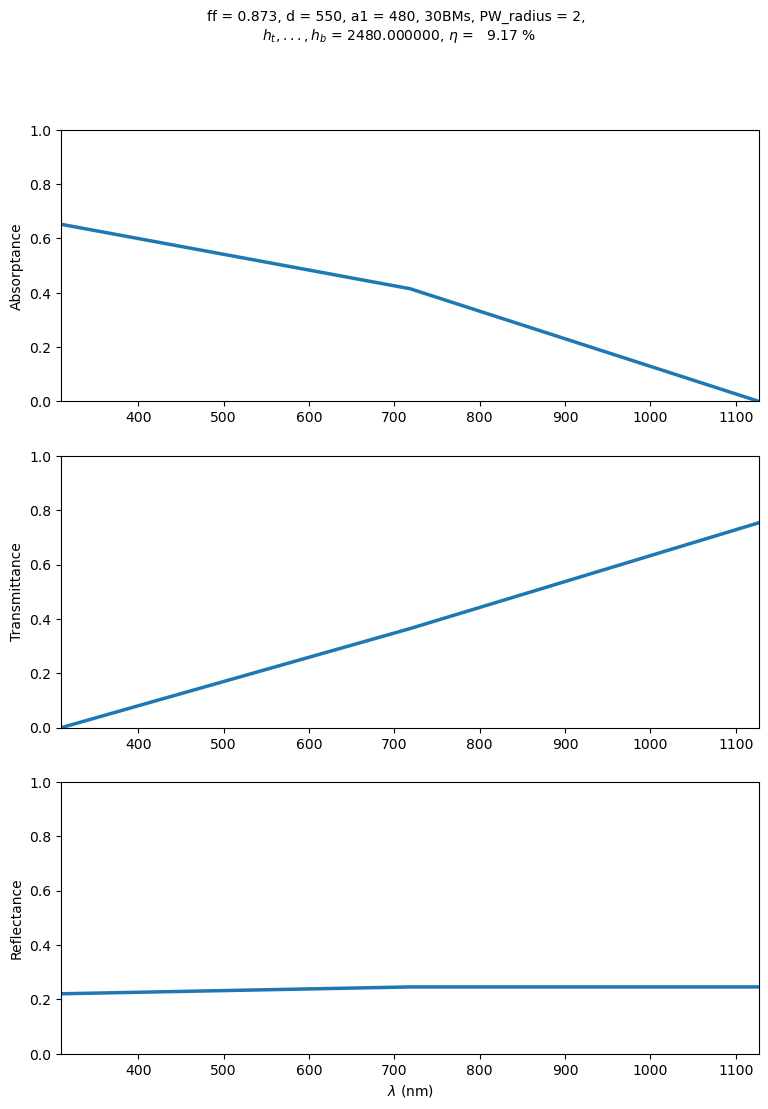

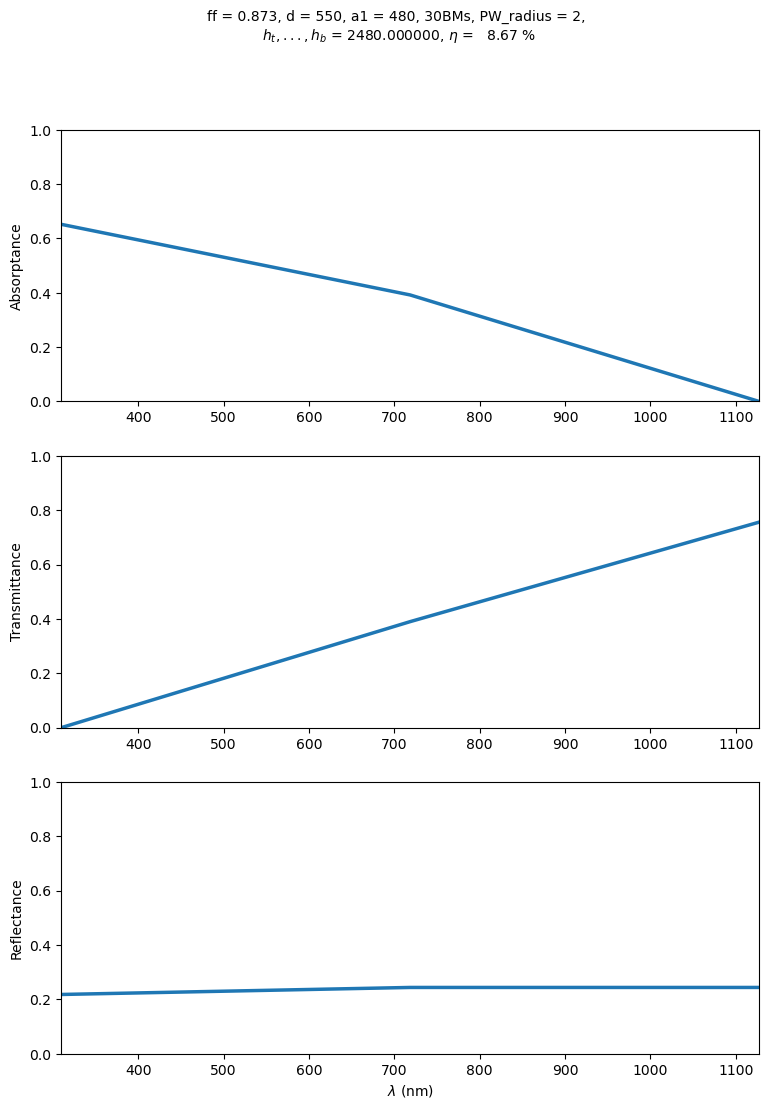

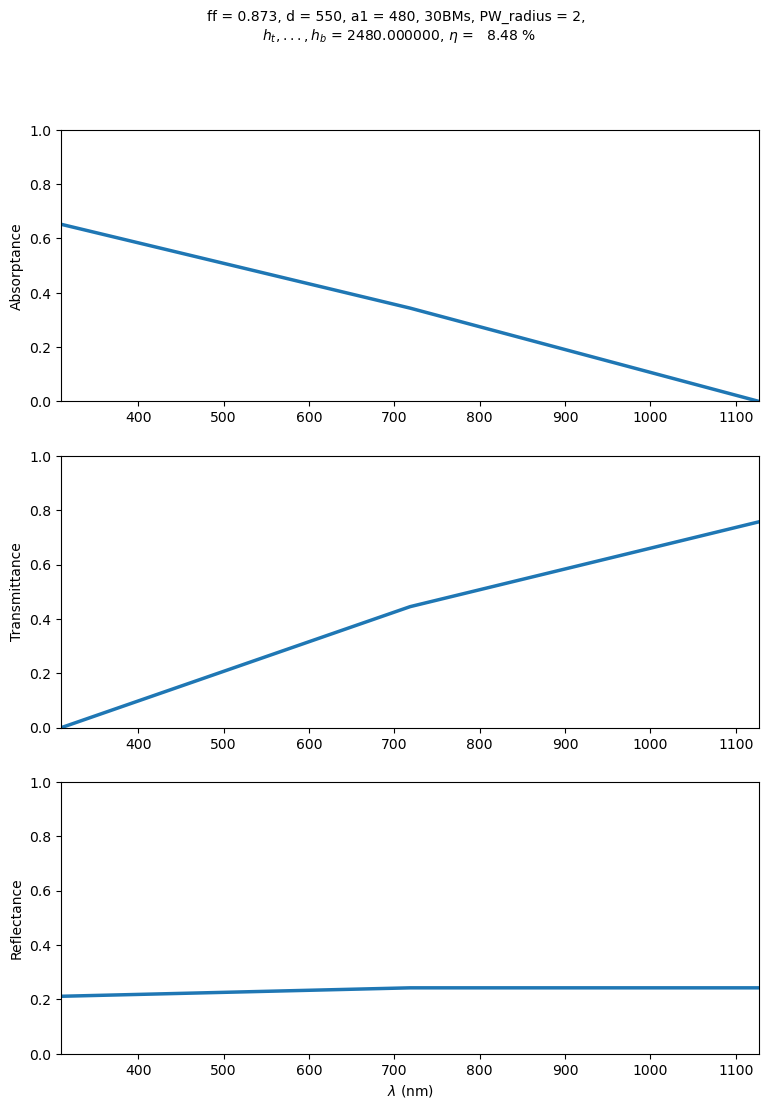

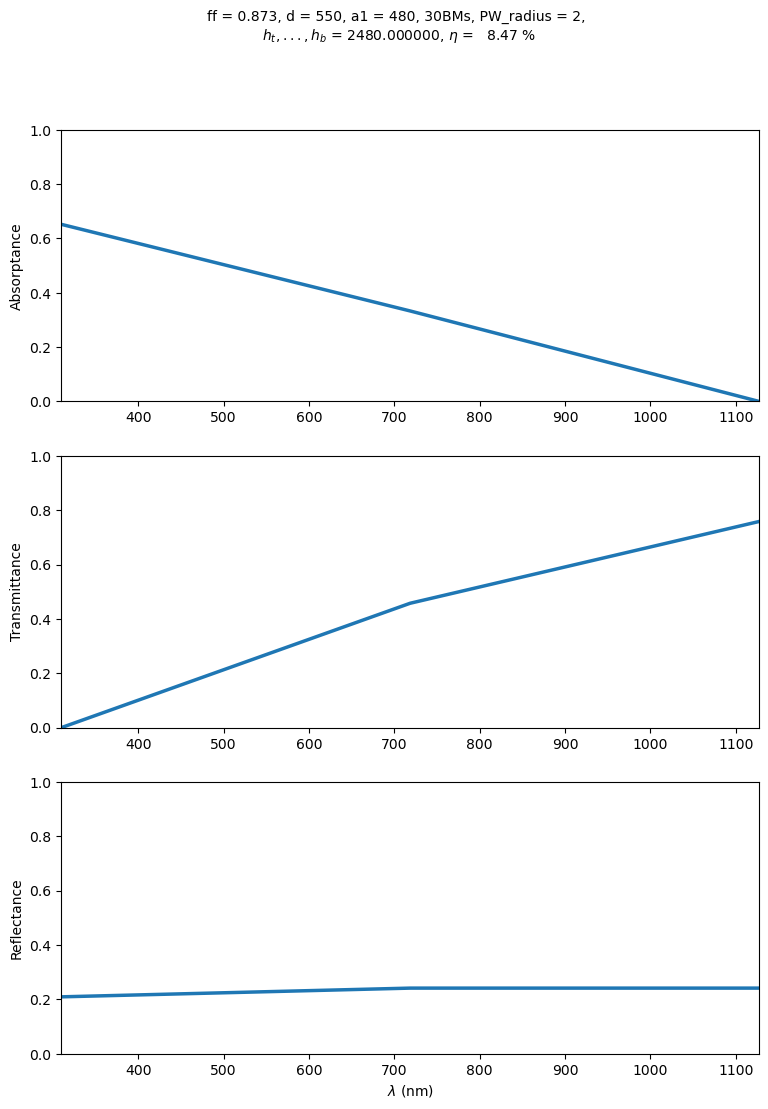

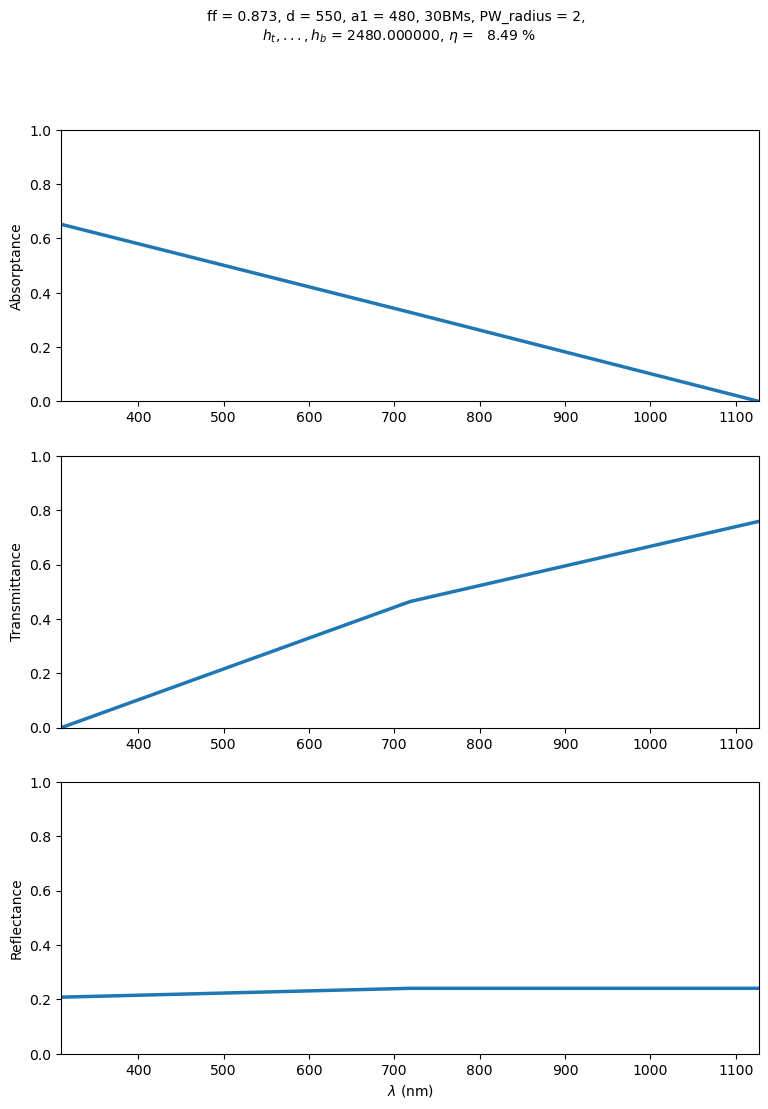

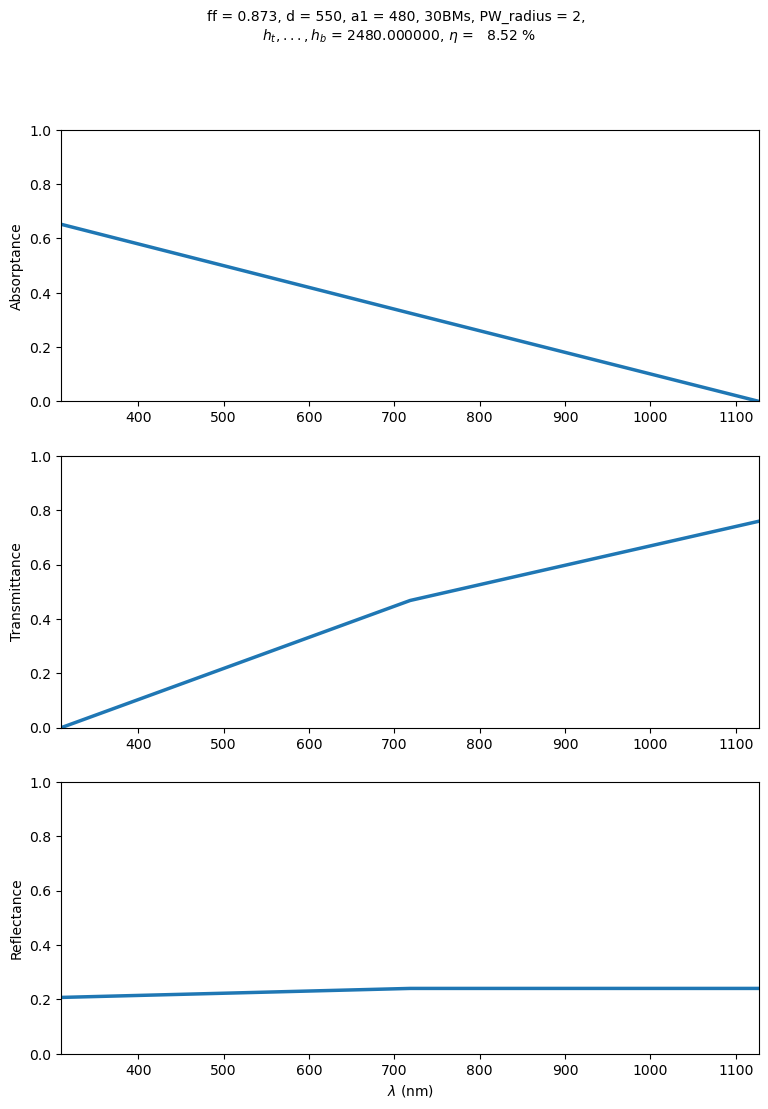

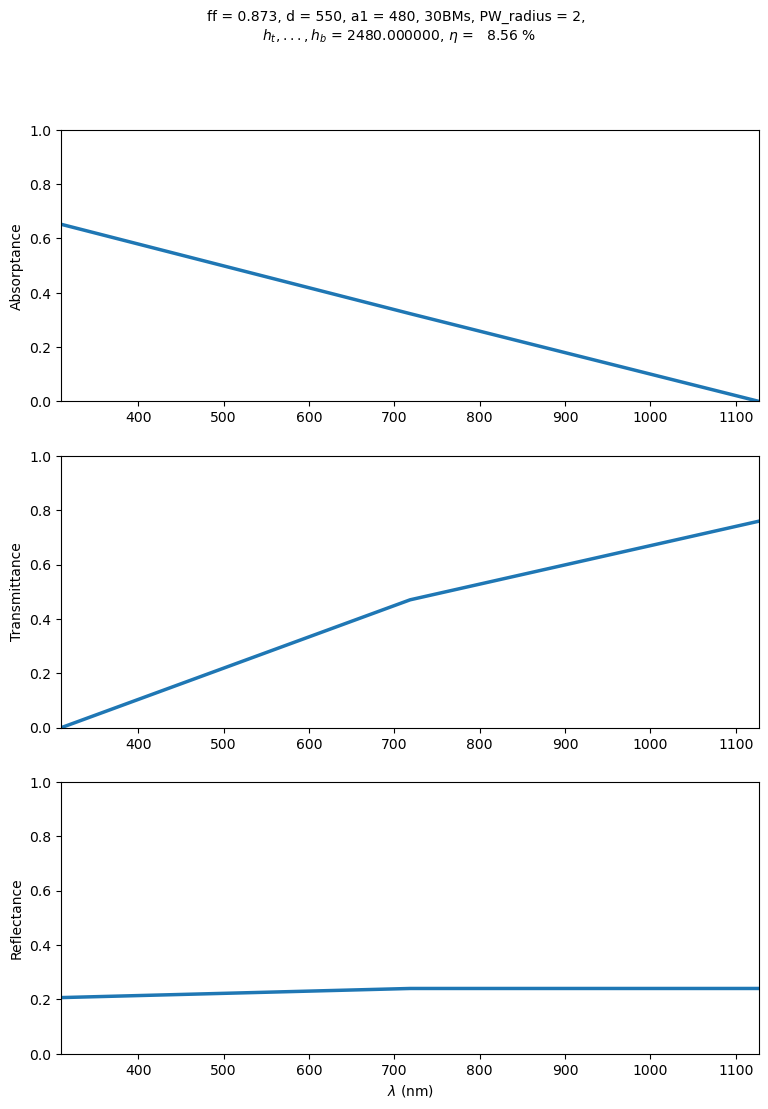

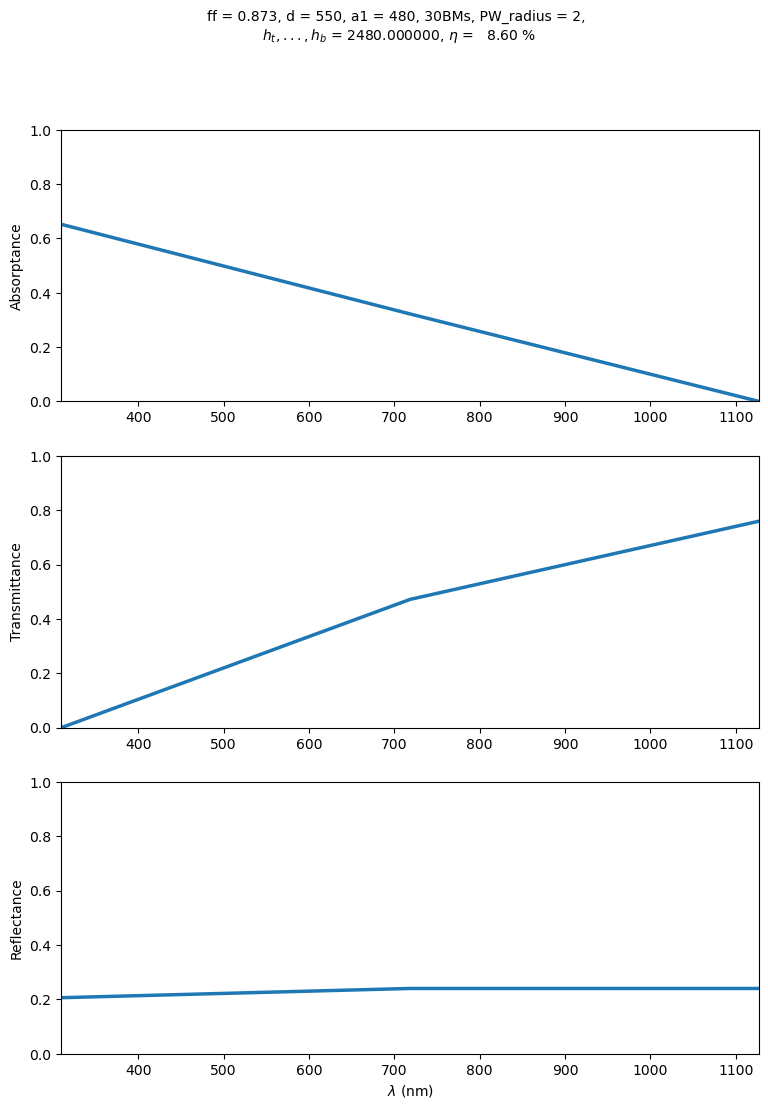

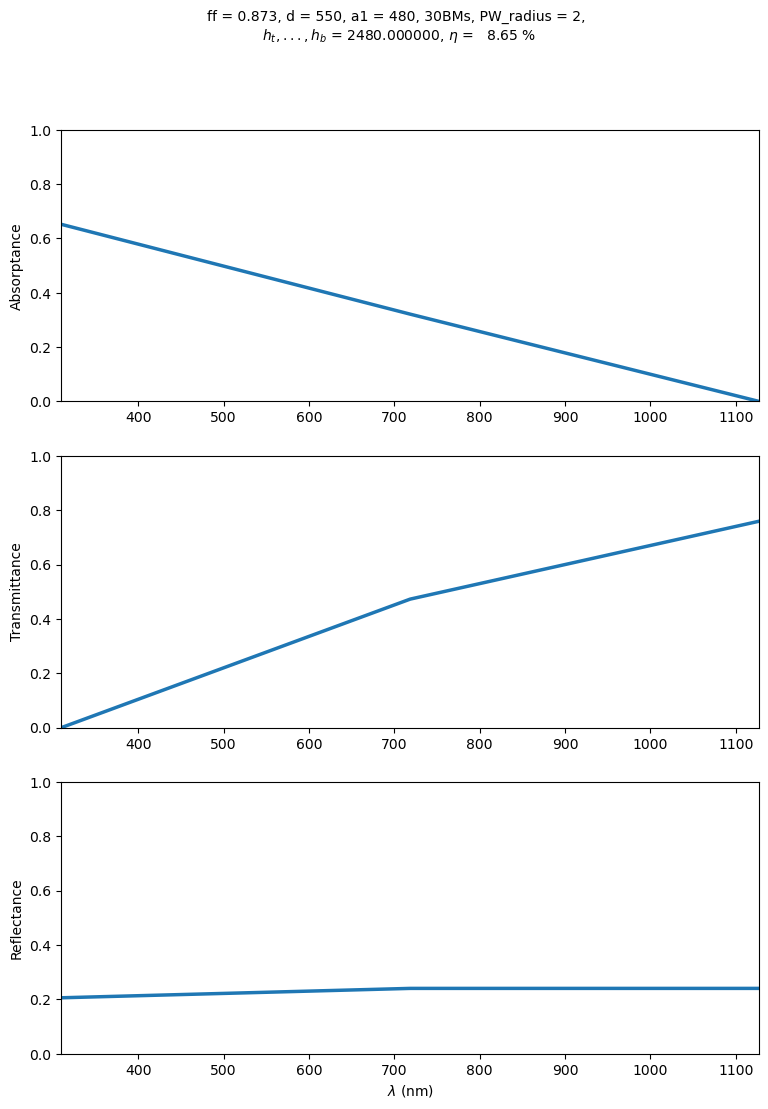

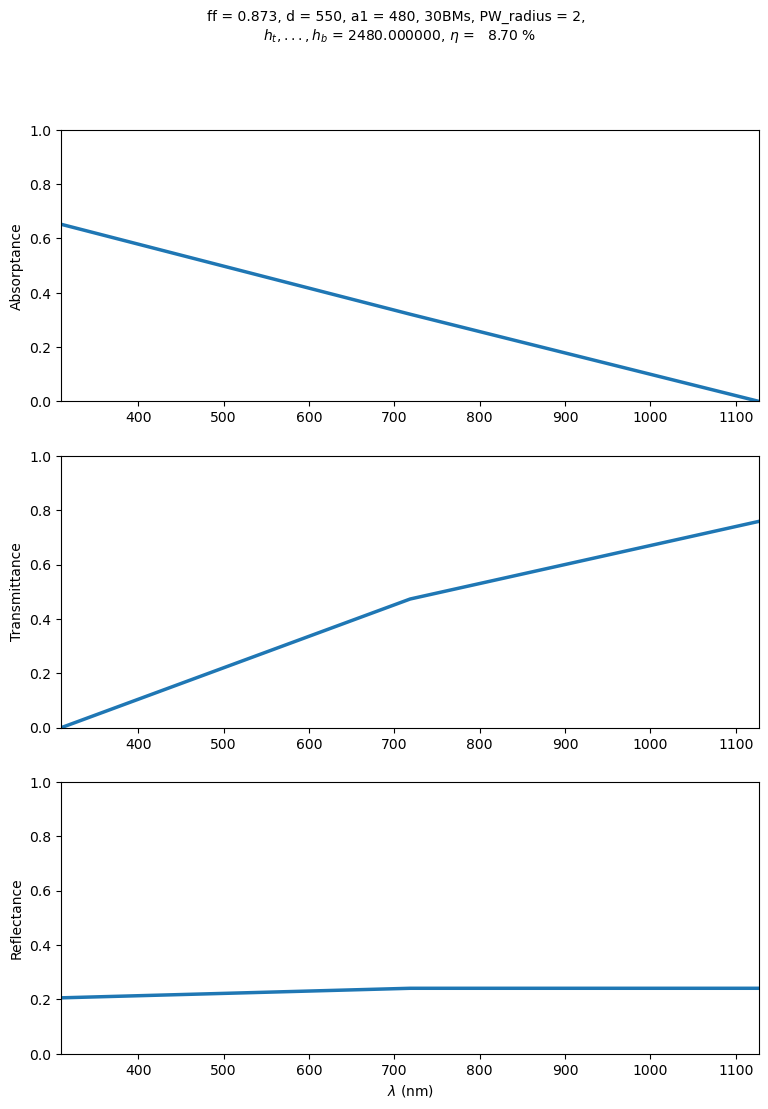

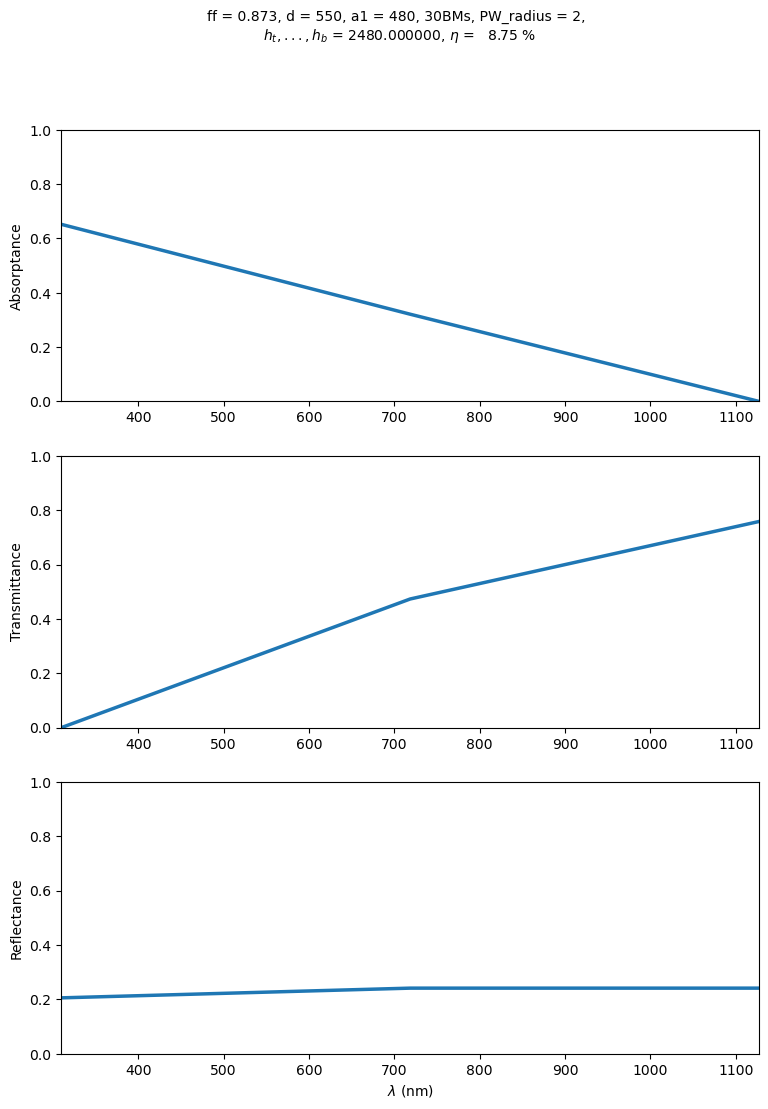

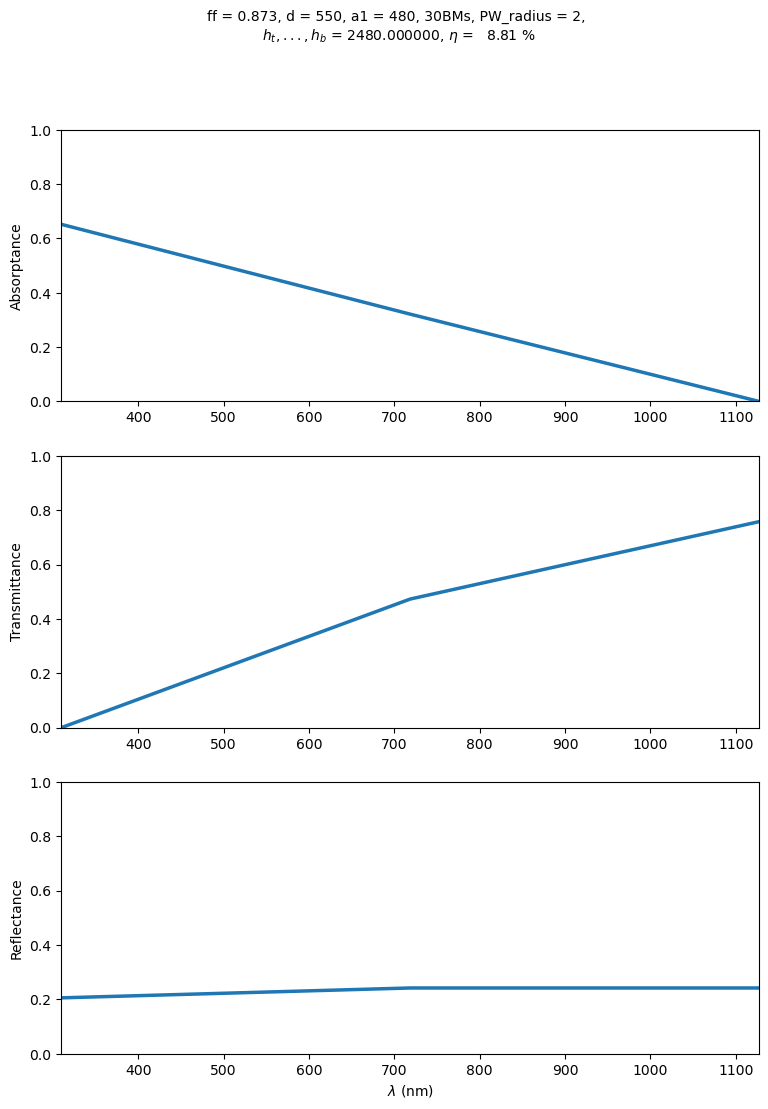

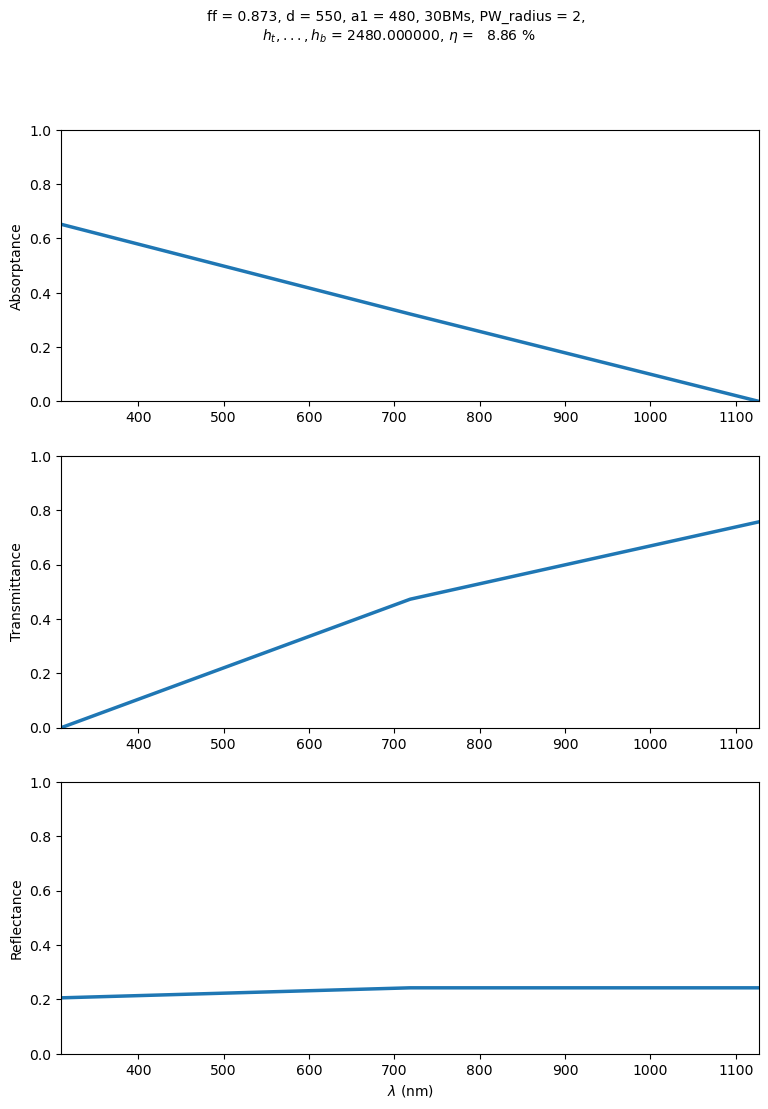

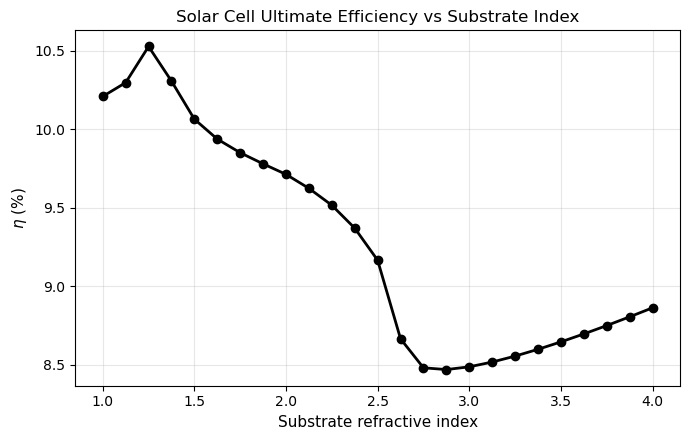

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from EMUstack.backend import materials, objects, plotting
from EMUstack.backend.stack import Stack

wl_1 = 310.0
wl_2 = 1127.0
no_wl_1 = 3
wavelengths = np.linspace(wl_1, wl_2, no_wl_1)
light_list = [objects.Light(wl, max_order_PWs=2, theta=0.0, phi=0.0) for wl in wavelengths]

period = 550.0
cover = objects.ThinFilm(period=period, height_nm='semi_inf', material=materials.Air, world_1d=True, loss=True)

sub_ns = np.linspace(1.0, 4.0, 25)
num_h = 11
heights = np.linspace(2180.0, 2480.0, num_h)

NW_diameter = 480.0
NWs = objects.NanoStruct(
    '1D_array', period, NW_diameter, height_nm=2330.0,
    inclusion_a=materials.Si_c, background=materials.Air, loss=True,
    make_mesh_now=True, force_mesh=False, lc_bkg=0.17, lc2=2.5
)

def simulate_stack(light):
    sim_cover = cover.calc_modes(light)
    sim_NWs   = NWs.calc_modes(light, num_BMs=30)
    stack_list = []
    for s in sub_ns:
        sub = objects.ThinFilm(period=period, height_nm='semi_inf', material=materials.Material(s + 0.0j), loss=False, world_1d=True)
        sim_sub = sub.calc_modes(light)
        avg_t, avg_r, avg_a = 0.0, 0.0, 0.0
        for h in heights:
            stk = Stack((sim_sub, sim_NWs, sim_cover), heights_nm=[h])
            stk.calc_scat(pol='TE')
            avg_t += stk.t_list[-1] / num_h
            avg_r += stk.r_list[-1] / num_h
            avg_a += stk.a_list[-1] / num_h
        stk.t_list[-1] = avg_t
        stk.r_list[-1] = avg_r
        stk.a_list[-1] = avg_a
        stack_list.append(stk)
    return stack_list

stacks_list = [simulate_stack(l) for l in light_list]

eta = []
for s in range(len(sub_ns)):
    stack1_wl = [stacks_list[i][s] for i in range(len(wavelengths))]
    eff = plotting.t_r_a_plots(stack1_wl, ult_eta=True, stack_label=s, add_name=str(s))
    eta.append(100.0 * eff[0])

fig, ax = plt.subplots(figsize=(7, 4.5), dpi=100)
ax.plot(sub_ns, eta, 'k-o', lw=2)
ax.set_xlabel('Substrate refractive index', fontsize=11)
ax.set_ylabel(r'$\eta$ (%)', fontsize=11)
ax.set_title('Solar Cell Ultimate Efficiency vs Substrate Index', fontsize=12)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


## Grating Mode Calculation & Substrate Sweep


## Thickness-Averaged Absorption vs Substrate Index


## Physical Interpretation
- Reusing the nanostructure S-matrix eliminates the computational cost of recalculating internal eigenmodes for every substrate configuration.
- Averaging over multiple heights suppresses sharp coherent interference fringes, modeling incoherent substrate transmission.
